# Evaluate generative models

In [1]:
import sys; sys.path.insert(0, '../scripts'); sys.path.insert(0, 'scripts')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import evaluate as E, generative_metrics as GM, exchangeability as X
import fit_hmm as H, fit_hmm_stim as S

BOUTS = 'data/bouts_GsizeMotionSingle.csv'
try:
    df = E.load_bouts(BOUTS)
except FileNotFoundError:
    df = E.load_bouts('../' + BOUTS)
records = E.build_records(df, min_len=10)   # abs_dict/roi optional (rich model)
print(f'{len(records)} fish; bouts/fish:')
pd.Series({f: r.n for f, r in sorted(records.items())}, name='n_bouts').to_frame().T

15 fish; bouts/fish:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
n_bouts,4272,5273,5526,4816,3258,6686,3137,6378,3199,4550,3129,6143,5674,3824,4725


## 0 - Likelihood per-bout metric

Likelihood defined as sum of one-step predictive log-score.

Per-bout predictive log-density must sum to exact joint-likelihood from model's own forward-backward pass, and reproduce each model's loglikelihood. Check is done here, where max_abs_diff should be 0.

In [2]:
import os
def _p(rel):
    return rel if os.path.exists(rel) else '../' + rel

In [3]:
spont = H.load_hmm(_p('data/hmm_GsizeMotionSingle.npz'))
simple = S.load_model(_p('data/hmm_stim_GsizeMotionSingle.npz'))
E.identity_check(records, spont_model=spont, simple_model=simple).round(6)

,model,max_abs_diff,total_loglik,stored_loglik
0,spontaneous,0.0,-384260.436459,-384260.436460
1,simple_stim,0.0,-383457.138109,-383457.138564


## 1 - Individuality in fish behaviour ?

### 1.1 Transition matrix homogeneity

Each fish dynamics summarized by transition matrix (L, F, R). We compare fish using JS divergence (similar to KL divergence but symmetric, meaning JS(p, q) = JS(q, p)) and their average accross all fish.  

between_mean     0.0136
between_median   0.0095
within_mean      0.0031
within_median    0.0024
ratio_mean       4.3537
ratio_median     3.8715


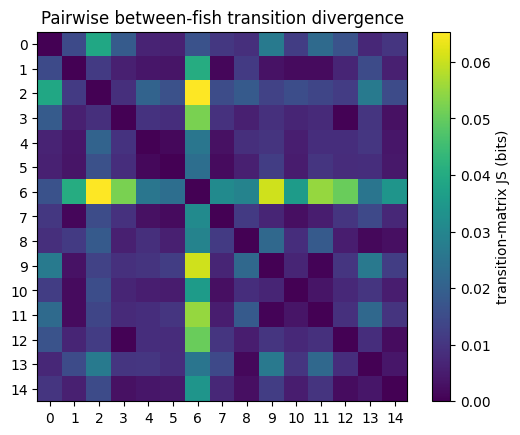

In [4]:
summ, D, fids = X.transition_homogeneity(records)
for k, v in summ.items(): print(f'{k:16s} {v:.4f}')
im = plt.imshow(D, cmap='viridis'); plt.colorbar(im, label='transition-matrix JS (bits)')
plt.xticks(range(len(fids)), fids); plt.yticks(range(len(fids)), fids)
plt.title('Pairwise between-fish transition divergence'); plt.show()

Fish 6 stands out in transition dynamics.

### 1.2 "Pooling gap" - cost of training on fish itself vs on other fish

Measures likelihood gap of training a spontaneuous HMM model on the first half of every fish vs training on all the other fish. Even though this measure is "biased" because training on all other fish allows for more data for model, it still shows if it matters where you train from.

Other measure that removes this bias would be to train on first half of fish vs first half of other fish chosen at random, but that measure is very noisy depending on fish chosen at random.

| column | meaning |
|---|---|
| `fish_id` | The held-out **target** fish (the one being scored). |
| `n_test` | Number of bouts in that fish's **late half** — the held-out data all three models are scored on. |
| `personalized` | `L_self`: score of a model **trained on fish `f`'s own early half** (~½ a fish of data). The "best case" — the model has seen this individual. |
| `pooled_full` | `L_pool`: score of a model **trained on all ~14 other fish** (lots of data, but never this fish). This is the real leave-fish-out regime. |
| `pooled_matched` | `L_match`: score of a model **trained on one other fish, truncated to the same ~`n` bouts** as `personalized`. Same *data volume* as personalized, but from a *different individual* — isolates individuality from data amount. |
| `gap_full` | `personalized − pooled_full`. The **practical cost of LOFO**: it nets the individuality penalty against the pool's ~14× data advantage, so it comes out **small**. |
| `gap_matched` | `personalized − pooled_matched`. The **pure cost of individuality** at fixed data volume (self vs. a stranger, same #bouts) → typically **larger** than `gap_full`. |


In [5]:
pg = X.pooling_gap(records, model_factory=lambda: E.SpontaneousHMM(restarts=1, max_iter=30), seed=0)
display(pg.round(4))
print('median gap_full = %.4f  |  median gap_matched = %.4f  nats/bout'
      % (pg.gap_full.median(), pg.gap_matched.median()))
pg.set_index('fish_id')[['gap_full','gap_matched']].plot.bar(); plt.ylabel('personalized - pooled (nats/bout)')
plt.axhline(0, c='k', lw=.7); plt.title('Cost of treating fish as exchangeable'); plt.show()

KeyboardInterrupt: 

We can see that we are at a gap of approx. 0.033 nats/bout. This is very small in reference to per-bout log-likelihood of -5.4, meaning gap of only 0.6% of per-bout log-likelihood.

Still fish 14 is an outlier.

### 1.3 Learning curve vs number of training fish

Measures gain in likelihood by adding more fish to train from. Ex : if num of training fish is 2, stdev shows difference in achieved log likelihood on held out test set depending on combination of fish chosen for training.
Held-out test set are fish 6, 7, 11 everytime.

,n_train_fish,mean,std,count
0,1,-5.4941,0.0000,3
1,2,-5.4688,0.0254,3
2,4,-5.4543,0.0041,3
3,8,-5.4495,0.0016,3
4,12,-5.4466,0.0000,3


held-out fish: [np.int64(8), np.int64(7), np.int64(11)]


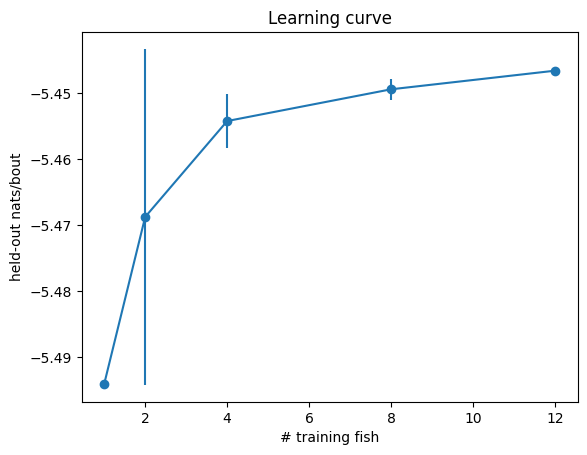

In [ ]:
raw, agg, holdout = X.learning_curve(records, sizes=(1,2,4,8,12), n_holdout=3, n_draws=3,
                                     model_factory=lambda: E.SpontaneousHMM(restarts=1, max_iter=30))
display(agg.round(4)); print('held-out fish:', holdout)
plt.errorbar(agg.n_train_fish, agg['mean'], yerr=agg['std'], marker='o')
plt.xlabel('# training fish'); plt.ylabel('held-out nats/bout'); plt.title('Learning curve'); plt.show()

Shows little gain adding fish in training set from 8 fish onwards ("plateau"). 

### 1.4 Ward clustering

Clustering of fish on standardized summary statistics.

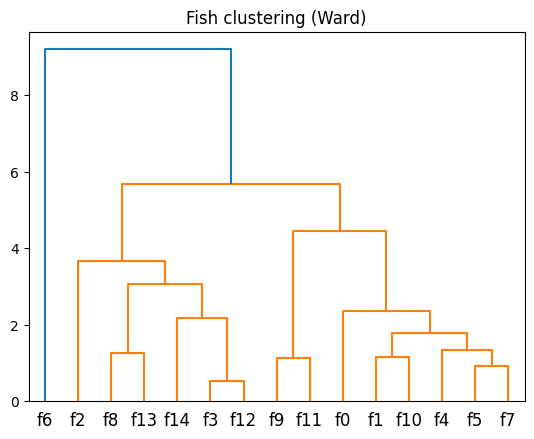

cluster labels: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 2, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1}


,forward_fraction,abs_dtheta_median,bout_rate_hz,lr_bias,turn_stay,p_ff
0,0.181,33.690,0.625,-0.065,0.491,0.181
1,0.092,37.057,0.769,-0.057,0.461,0.121
2,0.064,45.000,0.833,0.149,0.432,0.085
3,0.079,40.914,0.698,0.060,0.535,0.105
4,0.133,31.985,0.732,-0.088,0.457,0.145
5,0.138,35.134,0.833,-0.013,0.445,0.142
6,0.278,23.666,1.500,-0.020,0.368,0.337
7,0.116,35.781,0.937,-0.062,0.440,0.132
8,0.130,37.551,0.857,0.118,0.524,0.173
9,0.062,51.340,0.667,-0.117,0.466,0.093


In [ ]:
labels, Z, feat = X.cluster_fish(records, n_clusters=2)
from scipy.cluster.hierarchy import dendrogram
dendrogram(Z, labels=[f'f{f}' for f in feat.index]); plt.title('Fish clustering (Ward)'); plt.show()
print('cluster labels:', labels)
display(feat.round(3))

| column | meaning | reading |
|---|---|---|
| `forward_fraction` | Fraction of bouts that are **Forward** (\|Δθ\| < 10°) | higher = swims straighter; lower = turns more often |
| `abs_dtheta_median` | **Median absolute reorientation angle** \|Δθ\| (degrees) | higher = larger typical turns |
| `bout_rate_hz` | **Bout frequency** = 1 / median(inter-bout interval), in Hz | higher = bouts more often (shorter gaps) |
| `lr_bias` | **Left/right handedness** = P(Right) − P(Left) | ≈ 0 = symmetric; > 0 = turns right more; < 0 = left more |
| `turn_stay` | **Turn persistence** = ½·(P(L→L) + P(R→R)) from the transition matrix | higher = once turning, keeps turning the *same* way (handed streaks) |
| `p_ff` | **Forward stickiness** = P(F→F), the top-left transition entry | higher = a forward bout tends to be followed by another forward bout |



## 2 - Metric A : Predictive likelihood

Run the 12-3 cross-validation for every model.

In [ ]:
strata = X.strata_from_clusters(records, n_clusters=2)
folds = E.make_folds(sorted(records), n_folds=5, strata=strata, seed=0)
print('fold test groups:', [t for _, t in folds])
# restarts=1, capped max_iter keep the walkthrough responsive; raise both for final numbers
facs = E.default_model_factories(restarts=1, max_iter=120, include_rich=False)
likA = E.cross_validate_likelihood(records, facs, folds, verbose=True)
likA = E.add_skill_scores(likA)
likA.head()

fold test groups: [[3, 8, 10], [2, 13, 14], [0, 9, 11], [1, 5, 12], [4, 6, 7]]
  fold 0: trained on 12 fish, scored [3, 8, 10]
  fold 1: trained on 12 fish, scored [2, 13, 14]
  fold 2: trained on 12 fish, scored [0, 9, 11]
  fold 3: trained on 12 fish, scored [1, 5, 12]
  fold 4: trained on 12 fish, scored [4, 6, 7]


,fish_id,model,n_bouts,nats_per_bout,bits_per_bout,nats_stim,nats_nostim,n_stim,symbol_nats_per_bout,symbol_bits_per_bout,symbol_perplexity,fold,density_skill_bits,symbol_skill_bits
0,3,marginal_density,4817,-5.461088,7.878684,-5.575108,-5.391908,1819.0,-0.932713,1.345621,2.541395,0,0.0,-0.025814
1,8,marginal_density,3197,-5.547449,8.003277,-5.625088,-5.503653,1153.0,-0.992759,1.432248,2.698669,0,0.0,-0.012788
2,10,marginal_density,3141,-5.497434,7.931121,-5.430201,-5.542590,1262.0,-0.944994,1.363338,2.572798,0,0.0,-0.018009
3,3,unigram,4817,NaN,NaN,NaN,NaN,NaN,-0.922971,1.331566,2.516758,0,NaN,-0.011760
4,8,unigram,3197,NaN,NaN,NaN,NaN,NaN,-0.993891,1.433882,2.701727,0,NaN,-0.014422


**Identifiers**
| column | meaning |
|---|---|
| `fish_id` | Which held-out fish this row scores. |
| `model` | Which model produced the scores (HMMs or baselines). |
| `fold` | Which CV fold this fish was held out in. |
| `n_bouts` | Number of bouts in the fish's sequence (predictions averaged over). |
| `n_stim` | How many of those bouts had a **moving stimulus** (sample size behind `nats_stim`). |

**Primary track — continuous turn-angle density**
| column | meaning | better = |
|---|---|---|
| `nats_per_bout` | Mean per-bout predictive **log-density** of Δθ, `mean_t log p(Δθ_t \| past, stim)`. *This is the headline Metric A number.* (A log-density → negative/large; only differences between models are meaningful.) | higher |
| `bits_per_bout` | Same as a cross-entropy cost: `−nats_per_bout / ln2`. | lower |
| `nats_stim` | `nats_per_bout` restricted to **stimulus-present** bouts (where stimulus models should shine). | higher |
| `nats_nostim` | `nats_per_bout` on **stimulus-absent** bouts. | higher |

`nats_per_bout` is the count-weighted average of `nats_stim` and `nats_nostim`.

**Secondary track — 3-symbol {F,L,R}**
| column | meaning | better = |
|---|---|---|
| `symbol_nats_per_bout` | Mean per-bout log-**probability** of the correct symbol (a mass, so always ≤ 0). | higher |
| `symbol_bits_per_bout` | Same in bits (cross-entropy over the 3 symbols). Uniform guess = `log₂3 ≈ 1.585` bits. | lower |
| `symbol_perplexity` | `exp(−symbol_nats) = 2^symbol_bits` = effective number of equally-likely symbols (1 = perfect, 3 = clueless). | lower |

*The density track and symbol track are **not comparable to each other** — one is a continuous density, the other a probability over 3 outcomes.*

**Skill scores (bits saved per bout vs. a baseline; higher = better)**
| column | meaning |
|---|---|
| `density_skill_bits` | `bits(marginal_density) − bits(model)` — the value of the model's *dynamics/stimulus* over a no-dynamics baseline. `marginal_density` itself = 0. |
| `symbol_skill_bits` | `symbol_bits(bigram) − symbol_bits(model)` — value beyond a *first-order Markov* baseline. `bigram` itself = 0; `unigram` is typically negative. |


### 2.1 - Aggregate result per model

,model,metric,mean,mean_lo,mean_hi,median,n_fish
2,simple_stim,bits_per_bout,7.8561,7.7630,7.9783,7.8066,15
3,spontaneous,bits_per_bout,7.8734,7.7809,7.9928,7.8259,15
1,marginal_density,bits_per_bout,7.8865,7.7904,8.0069,7.8562,15
0,bigram,bits_per_bout,NaN,NaN,NaN,NaN,0
4,unigram,bits_per_bout,NaN,NaN,NaN,NaN,0


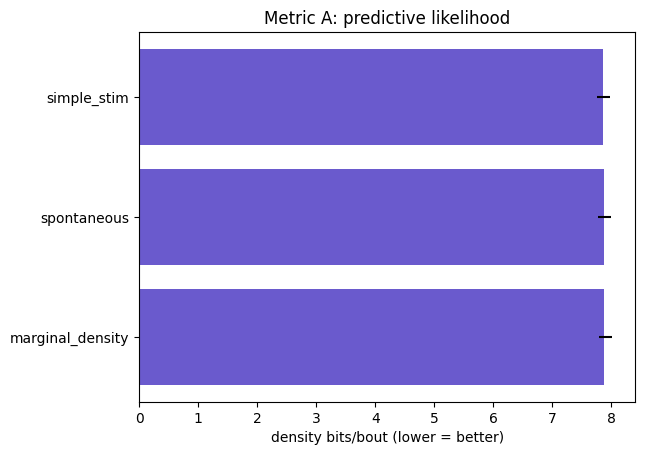

In [ ]:
sumA = E.summarize(likA, metric='bits_per_bout')
display(sumA.round(4))
d = sumA.dropna(subset=['mean'])
plt.barh(d.model, d['mean'], xerr=[d['mean']-d.mean_lo, d.mean_hi-d['mean']], color='slateblue')
plt.xlabel('density bits/bout (lower = better)'); plt.title('Metric A: predictive likelihood'); plt.gca().invert_yaxis(); plt.show()

How much is saved compared to baseline by each model

In [ ]:
sk = E.summarize(likA, metric='density_skill_bits')
display(sk.dropna(subset=['mean']).round(4))
print('symbol-track skill vs bigram:')
display(E.summarize(likA, metric='symbol_skill_bits').dropna(subset=['mean']).round(4))

,model,metric,mean,mean_lo,mean_hi,median,n_fish
1,marginal_density,density_skill_bits,0.0000,0.0000,0.0000,0.0000,15
3,spontaneous,density_skill_bits,0.0131,0.0053,0.0210,0.0161,15
2,simple_stim,density_skill_bits,0.0304,0.0198,0.0411,0.0337,15


symbol-track skill vs bigram:


,model,metric,mean,mean_lo,mean_hi,median,n_fish
1,marginal_density,symbol_skill_bits,-0.0088,-0.0168,-0.0003,-0.0128,15
4,unigram,symbol_skill_bits,-0.0070,-0.0117,-0.0026,-0.0078,15
0,bigram,symbol_skill_bits,0.0000,0.0000,0.0000,0.0000,15
3,spontaneous,symbol_skill_bits,0.0017,-0.0001,0.0033,0.0016,15
2,simple_stim,symbol_skill_bits,0.0181,0.0127,0.0235,0.0185,15


### 2.2 - Performance comparison on bouts with stimulus

Only a minority of bouts have a moving stimulus, so a real following effect is
diluted in the overall average.

,nats_per_bout,nats_stim,nats_nostim
model,,,
marginal_density,-5.4665,-5.5213,-5.4349
simple_stim,-5.4454,-5.4791,-5.4260
spontaneous,-5.4574,-5.5105,-5.4268


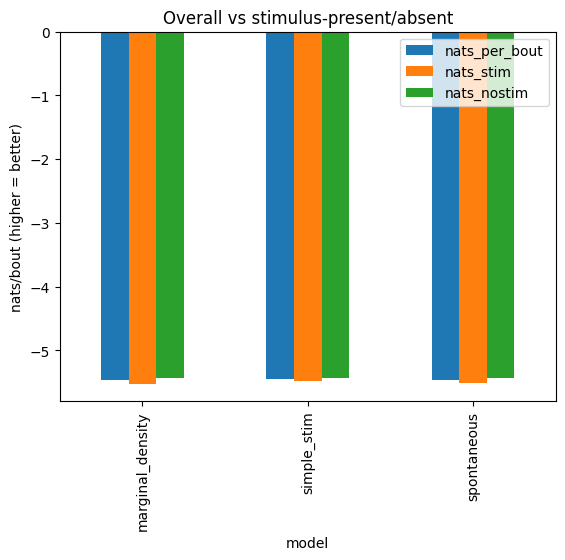

In [ ]:
strat = likA.dropna(subset=['nats_stim']).groupby('model')[['nats_per_bout','nats_stim','nats_nostim']].mean()
display(strat.round(4))
strat.plot.bar(); plt.ylabel('nats/bout (higher = better)'); plt.title('Overall vs stimulus-present/absent'); plt.show()

### 2.3 - Model comparison per fish

We can see hmm model outperforms baseline on almost every fish. 

,model_a,model_b,metric,n_fish,prefer_a,prefer_b,ties,median_delta,delta_lo,delta_hi,wilcoxon_p,sign_test_p
0,simple_stim,spontaneous,nats_per_bout,15,14,1,0,0.0133,0.0074,0.0164,0.0003,0.0010
1,spontaneous,marginal_density,nats_per_bout,15,13,2,0,0.0112,0.0035,0.0127,0.0084,0.0074
2,bigram,unigram,nats_per_bout,0,0,0,0,NaN,NaN,NaN,NaN,NaN


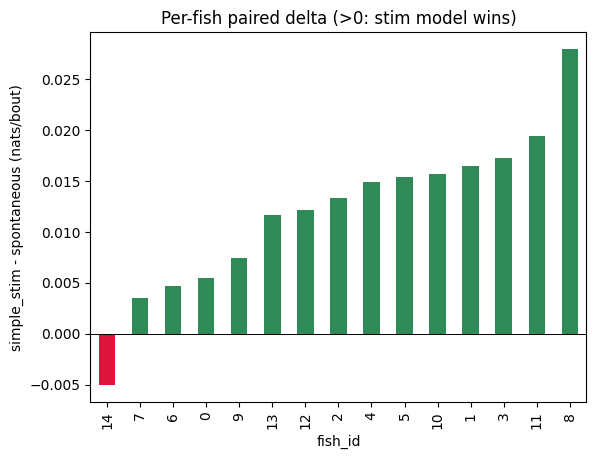

In [ ]:
pairs = [('simple_stim','spontaneous'), ('spontaneous','marginal_density'), ('bigram','unigram')]
rs = X.rank_stability(likA, pairs, metric='nats_per_bout', higher_better=True)
display(rs.round(4))
# per-fish paired deltas for the headline pair
a = likA[likA.model=='simple_stim'].set_index('fish_id')['nats_per_bout']
b = likA[likA.model=='spontaneous'].set_index('fish_id')['nats_per_bout']
delta = (a-b).sort_values()
delta.plot.bar(color=['crimson' if v<0 else 'seagreen' for v in delta]); plt.axhline(0,c='k',lw=.7)
plt.ylabel('simple_stim - spontaneous (nats/bout)'); plt.title('Per-fish paired delta (>0: stim model wins)'); plt.show()

## 3 - Metric B : Do free-run samples look real ?

Metric A is a good measure for predictabililty, but doesn't measure if generated trajectories over long rollouts statistically match real ones. Metric B is a better measure for this.

We teacher-force each held-out fish's real stimulus stream, draw
R rollouts matched to the real bout count, and compare distributions/structure.

*(Refits the models per fold and samples R&times;15 fish &mdash; a few minutes; raise `R` for tighter Monte-Carlo CIs.)*

In [ ]:
panel, wins = GM.cross_validate_generative(records, facs, folds, R=12, W=60, verbose=True)
sumB = GM.summarize_panel(panel)
cols = ['model','abs_dtheta_w1','symbol_js','dt_w1','dist_w1','trans_js','acf_l2','runlen_w1','tuning_mse','following_gap']
display(sumB[[c for c in cols if c in sumB.columns]].round(4))

  fold 0: generative panel for test fish [3, 8, 10]
  fold 1: generative panel for test fish [2, 13, 14]
  fold 2: generative panel for test fish [0, 9, 11]
  fold 3: generative panel for test fish [1, 5, 12]
  fold 4: generative panel for test fish [4, 6, 7]


,model,abs_dtheta_w1,symbol_js,dt_w1,dist_w1,trans_js,acf_l2,runlen_w1,tuning_mse,following_gap
0,simple_stim,6.8175,0.0063,0.8262,0.8700,0.0080,0.0493,0.1390,0.0057,0.0365
1,spontaneous,6.7227,0.0062,0.8364,0.8736,0.0076,0.0516,0.1374,0.0210,0.1252


**Per-bout distributions (order doesn't matter)**
| column | what it measures | units |
|---|---|---|
| `abs_dtheta_w1` | Wasserstein-1 distance between the **\|Δθ\| distributions** — turn *magnitude* fidelity | degrees |
| `symbol_js` | Jensen–Shannon divergence between the **F/L/R marginal fractions** — right *mix* of forward/left/right | bits |
| `dt_w1` | Wasserstein-1 between **inter-bout-interval** distributions (bout rate) | seconds |
| `dist_w1` | Wasserstein-1 between **travel-distance** distributions (path length) | mm |

⚠️ `dt_w1` and `dist_w1` are **pool artifacts**: timing and distance are *resampled from the training pool*, not modeled, so these mostly test whether the pool matches this fish — not model quality. Don't read model quality into them.

**Sequential structure (order matters — the rollout-drift detectors)**
| column | what it measures | units |
|---|---|---|
| `trans_js` | Row-averaged JS between the **first-order transition matrices** — one-step "grammar" | bits |
| `acf_l2` | L2 distance between the **turn-sign autocorrelation curves** — *multi-step* structure (**primary drift detector**) | — |
| `runlen_w1` | Wasserstein-1 between **run-length distributions** (consecutive same-symbol streaks) — exploding/collapsed streaks | bouts |

**Stimulus response (the functional following test)**
| column | what it measures | units |
|---|---|---|
| `tuning_mse` | Mean-squared error between the **tuning curves** `P(rightward turn \| stimulus bearing)`, real vs generated — does it *steer* like a real fish? | — |
| `following_gap` | \|real − generated\| **following index** (`P(turn toward dots) − 0.5`) — does it reproduce the *strength* of following? | — |


Visual on some metrics

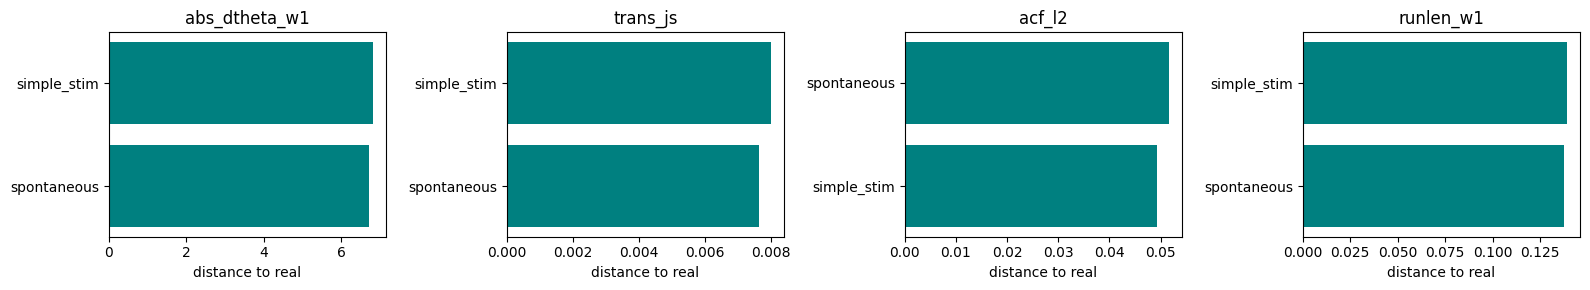

In [ ]:
mt = ['abs_dtheta_w1','trans_js','acf_l2','runlen_w1']
fig, axes = plt.subplots(1, len(mt), figsize=(4*len(mt),3))
for ax, m in zip(axes, mt):
    g = panel.groupby('model')[m].mean().sort_values()
    ax.barh(g.index, g.values, color='teal'); ax.set_title(m); ax.set_xlabel('distance to real')
plt.tight_layout(); plt.show()

### 3.1 - Does model follow stimulus ?

The following index is defined as : P(turn towards stimuli dots) - 0.5

,real_following_index,gen_following_index
model,,
simple_stim,0.125,0.121
spontaneous,0.125,-0.000


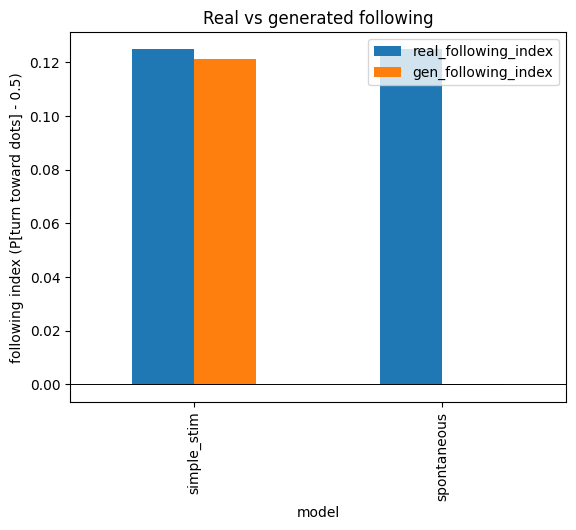

In [ ]:
fi = panel.groupby('model')[['real_following_index','gen_following_index']].mean()
display(fi.round(3))
fi.plot.bar(); plt.ylabel('following index (P[turn toward dots] - 0.5)')
plt.axhline(0, c='k', lw=.7); plt.title('Real vs generated following'); plt.show()

### 3.2 - Training RF classifier to identify real vs generated trajectories

In [ ]:
for name, wm in wins.items():
    auc, aucs = GM.c2st_auc(wm)
    print(f'{name:16s} C2ST AUC = {auc:.3f}')

spontaneous      C2ST AUC = 0.762
simple_stim      C2ST AUC = 0.753


Each **60-bout window** (real or generated) is summarised into these 20 features; the RandomForest is trained to tell real windows (label 1) from generated ones (label 0). It can only detect differences these features express.

| # | Feature | Group | Description |
|---|---|---|---|
| 1 | `P(F)` | symbol freq. | Fraction of **Forward** bouts (\|Δθ\| < 10°) in the window |
| 2 | `P(L)` | symbol freq. | Fraction of **Left** bouts (Δθ < −10°) |
| 3 | `P(R)` | symbol freq. | Fraction of **Right** bouts (Δθ > 10°) |
| 4 | `P(F→F)` | transition | Prob. a Forward is followed by a Forward (forward stickiness) |
| 5 | `P(F→L)` | transition | Forward → Left |
| 6 | `P(F→R)` | transition | Forward → Right |
| 7 | `P(L→F)` | transition | Left → Forward |
| 8 | `P(L→L)` | transition | Left → Left (left-turn persistence) |
| 9 | `P(L→R)` | transition | Left → Right (direction switching) |
| 10 | `P(R→F)` | transition | Right → Forward |
| 11 | `P(R→L)` | transition | Right → Left |
| 12 | `P(R→R)` | transition | Right → Right (right-turn persistence) |
| 13 | `mean(\|Δθ\|)` | magnitude | Mean absolute reorientation angle (typical turn size) |
| 14 | `std(\|Δθ\|)` | magnitude | Spread of turn magnitudes |
| 15 | `median(\|Δθ\|)` | magnitude | Median absolute angle (robust central turn size) |
| 16 | `q90(\|Δθ\|)` | magnitude | 90th percentile of \|Δθ\| (size of the big turns) |
| 17 | `ACF₁` | autocorrelation | Turn-sign autocorrelation (R=+1, L=−1, F=0) at lag 1 |
| 18 | `ACF₂` | autocorrelation | Turn-sign autocorrelation at lag 2 |
| 19 | `ACF₃` | autocorrelation | Turn-sign autocorrelation at lag 3 |
| 20 | `mean run-length` | streaks | Average length of consecutive same-symbol runs |